# Home Credit Default Risk: Classification Model

- Goal: predict whether a client will default (TARGET = 1)
- Data: application_train_clean.csv (307,511 loans)
- Challenge: imbalanced classes (92% repaid, 8% default)

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('../data/application_train_clean.csv')
df.shape

(307511, 125)

In [2]:
y = df['TARGET']
X = df.drop(columns=['TARGET', 'SK_ID_CURR', 'AGE_GROUP'])
X = pd.get_dummies(X, drop_first=True)
X.shape

(307511, 230)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
y_train.mean(), y_test.mean()

(np.float64(0.08072908198107379), np.float64(0.08072776937710356))

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier

model = HistGradientBoostingClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,max_iter,100
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [5]:
from sklearn.metrics import roc_auc_score, classification_report

y_proba = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

print('ROC AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred))

ROC AUC: 0.7591
              precision    recall  f1-score   support

           0       0.96      0.71      0.82     56538
           1       0.17      0.67      0.27      4965

    accuracy                           0.70     61503
   macro avg       0.56      0.69      0.54     61503
weighted avg       0.90      0.70      0.77     61503



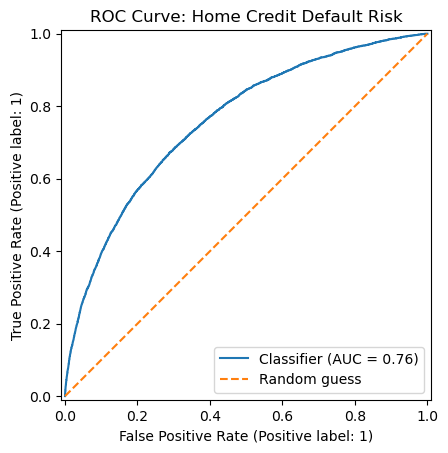

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random guess')
plt.title('ROC Curve: Home Credit Default Risk')
plt.legend()
plt.savefig('../outputs/roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Findings

1. The model reaches a ROC AUC of 0.76 on unseen data, clearly better than random guessing (0.50).
2. It finds 67% of the clients who default (recall), but only 17% of its risk flags are correct (precision), about twice the 8% base rate.
3. Accuracy (70%) is a misleading metric here, since a model that predicts "no default" for everyone would score 92%.
4. Using class_weight='balanced' trades precision for recall: more defaulters are caught, but more good clients are flagged.

## Next Steps

1. Add the other Kaggle tables (bureau, previous applications) to improve the ROC AUC.
2. Tune the decision threshold based on the cost of a missed default versus a rejected good client.
3. Explain the model with feature importance (permutation importance or SHAP).